README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

C:\Users\Divya\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Divya\.cache\huggingface\hub\datasets--fancyzhx--ag_news. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\Divya\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system 

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Dataset loaded successfully!
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

Category Distribution:
category
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64


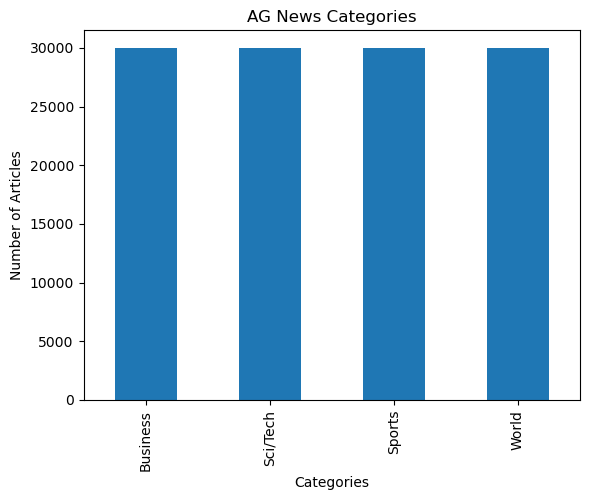

Map:   0%|          | 0/108000 [00:00<?, ? examples/s]

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]


Tokenization completed!
Input IDs: [101, 13905, 1998, 4963, 1999, 2235, 2845, 2237, 2044, 6859]
Attention Mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Training started...


C:\Users\Divya\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss


In [ ]:

# Transformer News Classifier using BERT

# 1. Install libraries
!pip install -q transformers datasets torch accelerate scikit-learn matplotlib seaborn

# 2. Import libraries
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# 3. Load AG News dataset
dataset = load_dataset("fancyzhx/ag_news")

categories = ["World", "Sports", "Business", "Sci/Tech"]

print("Dataset loaded successfully!")
print(dataset)

# 4. Explore categories
df = pd.DataFrame(dataset["train"])
df["category"] = df["label"].map(dict(enumerate(categories)))

print("\nCategory Distribution:")
print(df["category"].value_counts())

df["category"].value_counts().plot(kind="bar")
plt.title("AG News Categories")
plt.xlabel("Categories")
plt.ylabel("Number of Articles")
plt.show()

# 5. Split training and validation data
split = dataset["train"].train_test_split(
    test_size=0.1,
    seed=42
)

dataset = DatasetDict({
    "train": split["train"],
    "validation": split["test"],
    "test": dataset["test"]
})

dataset = dataset.rename_column("label", "labels")

# 6. Load BERT tokenizer
model_name = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

# 7. Tokenize news articles
def tokenize_data(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

tokenized_dataset = dataset.map(
    tokenize_data,
    batched=True,
    remove_columns=["text"]
)

print("\nTokenization completed!")
print("Input IDs:", tokenized_dataset["train"][0]["input_ids"][:10])
print("Attention Mask:", tokenized_dataset["train"][0]["attention_mask"][:10])

# 8. Load pretrained BERT model
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=4,
    id2label={i: name for i, name in enumerate(categories)},
    label2id={name: i for i, name in enumerate(categories)}
)

# 9. Define evaluation metrics
def compute_metrics(pred):
    labels = pred.label_ids
    predictions = np.argmax(pred.predictions, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

# 10. Set training parameters
training_args = TrainingArguments(
    output_dir="./news_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=2,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    report_to="none",
    fp16=torch.cuda.is_available()
)

# 11. Create Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    compute_metrics=compute_metrics
)

# 12. Train the model
print("\nTraining started...")
trainer.train()

# 13. Validate the model
print("\nValidation Results:")
print(trainer.evaluate())

# 14. Test the model
print("\nTesting the model...")

predictions = trainer.predict(tokenized_dataset["test"])

y_true = predictions.label_ids
y_pred = np.argmax(predictions.predictions, axis=1)

print("\nTest Accuracy:", accuracy_score(y_true, y_pred))

# 15. Classification report
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=categories,
    zero_division=0
))

# 16. Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=categories,
    yticklabels=categories
)

plt.title("Transformer News Classifier")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.show()

# 17. Predict a new news article
def predict_news(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    device = next(trainer.model.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    trainer.model.eval()

    with torch.no_grad():
        outputs = trainer.model(**inputs)

    probabilities = torch.softmax(outputs.logits, dim=1)

    prediction = torch.argmax(probabilities, dim=1).item()
    confidence = probabilities[0][prediction].item() * 100

    print("\nInput News:", text)
    print("Predicted Category:", categories[prediction])
    print("Confidence: {:.2f}%".format(confidence))

# 18. Get user input
news = input("\nEnter a news article: ")
predict_news(news)

# 19. Save the trained model
trainer.save_model("./BERT_News_Classifier")
tokenizer.save_pretrained("./BERT_News_Classifier")

print("\nModel saved successfully!")
